# Pandas intro — the most useful functions, step by step

**pandas** is the Python library for tables. Two objects do almost everything:

- **DataFrame** — a whole table (rows × named columns), like a spreadsheet;
- **Series** — one column of it.

Run the cells from top to bottom. Each step shows one idea on the same small table.

## 1. Create a table
A DataFrame can be built from a dictionary: keys become column names, lists become columns.

In [1]:
import pandas as pd

df = pd.DataFrame({
    "name":   ["Ala", "Bartek", "Celina", "Darek", "Ewa", "Filip", "Gosia", "Hubert"],
    "city":   ["Kraków", "Poznań", "Kraków", "Wrocław", "Warszawa", "Poznań", "Kraków", "Warszawa"],
    "grade":  [2, 3, 3, 1, 2, 3, 1, 2],
    "task_1": [85, 40, 92, 55, None, 70, 61, 77],
    "task_2": [60, 75, 88, None, 90, 45, 70, 82],
})
df

,name,city,grade,task_1,task_2
0,Ala,Kraków,2,85.0,60.0
1,Bartek,Poznań,3,40.0,75.0
2,Celina,Kraków,3,92.0,88.0
3,Darek,Wrocław,1,55.0,NaN
4,Ewa,Warszawa,2,NaN,90.0
5,Filip,Poznań,3,70.0,45.0
6,Gosia,Kraków,1,61.0,70.0
7,Hubert,Warszawa,2,77.0,82.0


## 2. Save and read a CSV file
Most data arrives as CSV. `to_csv` writes a file, `read_csv` reads it back (also from a URL).

In [2]:
df.to_csv("students.csv", index=False)
df = pd.read_csv("students.csv")

## 3. Look at the data first
`head` — first rows, `shape` — (rows, columns), `info` — column types and missing values, `describe` — statistics of numeric columns.

In [3]:
df.head(3)

,name,city,grade,task_1,task_2
0,Ala,Kraków,2,85.0,60.0
1,Bartek,Poznań,3,40.0,75.0
2,Celina,Kraków,3,92.0,88.0


In [4]:
df.shape

(8, 5)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   name    8 non-null      str    
 1   city    8 non-null      str    
 2   grade   8 non-null      int64  
 3   task_1  7 non-null      float64
 4   task_2  7 non-null      float64
dtypes: float64(2), int64(1), str(2)
memory usage: 452.0 bytes


In [6]:
df.describe()

,grade,task_1,task_2
count,8.000000,7.000000,7.000000
mean,2.125000,68.571429,72.857143
std,0.834523,18.026436,16.128945
min,1.000000,40.000000,45.000000
25%,1.750000,58.000000,65.000000
50%,2.000000,70.000000,75.000000
75%,3.000000,81.000000,85.000000
max,3.000000,92.000000,90.000000


## 4. Select columns
One name in brackets gives a **Series**; a list of names gives a smaller **DataFrame**.

In [7]:
df["city"]

0      Kraków
1      Poznań
2      Kraków
3     Wrocław
4    Warszawa
5      Poznań
6      Kraków
7    Warszawa
Name: city, dtype: str

In [8]:
df[["name", "task_1"]]

,name,task_1
0,Ala,85.0
1,Bartek,40.0
2,Celina,92.0
3,Darek,55.0
4,Ewa,NaN
5,Filip,70.0
6,Gosia,61.0
7,Hubert,77.0


## 5. Select rows: `iloc` and `loc`
`iloc` — by **position** (0, 1, 2…). `loc` — by **label** and with conditions; it can pick columns at the same time.

In [9]:
df.iloc[0:3]

,name,city,grade,task_1,task_2
0,Ala,Kraków,2,85.0,60.0
1,Bartek,Poznań,3,40.0,75.0
2,Celina,Kraków,3,92.0,88.0


In [10]:
df.loc[df["grade"] == 3, ["name", "grade"]]

,name,grade
1,Bartek,3
2,Celina,3
5,Filip,3


## 6. Filter rows with conditions
A condition gives True/False for every row; the table keeps the True rows. Combine conditions with `&` (and), `|` (or) — each in parentheses.

In [11]:
df[(df["city"] == "Kraków") & (df["task_1"] > 80)]

,name,city,grade,task_1,task_2
0,Ala,Kraków,2,85.0,60.0
2,Celina,Kraków,3,92.0,88.0


In [12]:
df[df["city"].isin(["Poznań", "Wrocław"])]

,name,city,grade,task_1,task_2
1,Bartek,Poznań,3,40.0,75.0
3,Darek,Wrocław,1,55.0,NaN
5,Filip,Poznań,3,70.0,45.0


## 7. Sort
`sort_values` sorts by a column; `ascending=False` puts the largest first.

In [13]:
df.sort_values("task_2", ascending=False)

,name,city,grade,task_1,task_2
4,Ewa,Warszawa,2,NaN,90.0
2,Celina,Kraków,3,92.0,88.0
7,Hubert,Warszawa,2,77.0,82.0
1,Bartek,Poznań,3,40.0,75.0
6,Gosia,Kraków,1,61.0,70.0
0,Ala,Kraków,2,85.0,60.0
5,Filip,Poznań,3,70.0,45.0
3,Darek,Wrocław,1,55.0,NaN


## 8. Missing values
`NaN` means *no value*. Count them with `isna().sum()`, then fill (`fillna`) or drop (`dropna`) — a choice you should make on purpose.

In [14]:
df.isna().sum()

name      0
city      0
grade     0
task_1    1
task_2    1
dtype: int64

In [15]:
df[["task_1", "task_2"]] = df[["task_1", "task_2"]].fillna(0)
df

,name,city,grade,task_1,task_2
0,Ala,Kraków,2,85.0,60.0
1,Bartek,Poznań,3,40.0,75.0
2,Celina,Kraków,3,92.0,88.0
3,Darek,Wrocław,1,55.0,0.0
4,Ewa,Warszawa,2,0.0,90.0
5,Filip,Poznań,3,70.0,45.0
6,Gosia,Kraków,1,61.0,70.0
7,Hubert,Warszawa,2,77.0,82.0


## 9. New columns
Arithmetic on columns works on every row at once — no loops needed.

In [16]:
df["total"] = df["task_1"] + df["task_2"]
df["passed"] = df["total"] >= 140
df

,name,city,grade,task_1,task_2,total,passed
0,Ala,Kraków,2,85.0,60.0,145.0,True
1,Bartek,Poznań,3,40.0,75.0,115.0,False
2,Celina,Kraków,3,92.0,88.0,180.0,True
3,Darek,Wrocław,1,55.0,0.0,55.0,False
4,Ewa,Warszawa,2,0.0,90.0,90.0,False
5,Filip,Poznań,3,70.0,45.0,115.0,False
6,Gosia,Kraków,1,61.0,70.0,131.0,False
7,Hubert,Warszawa,2,77.0,82.0,159.0,True


## 10. Count values
`value_counts` — how many times each value appears.

In [17]:
df["city"].value_counts()

city
Kraków      3
Poznań      2
Warszawa    2
Wrocław     1
Name: count, dtype: int64

## 11. Group and summarise
`groupby` splits the table into groups, then computes a statistic for each group — the most useful pandas idea.

In [18]:
df.groupby("city")["total"].mean()

city
Kraków      152.0
Poznań      115.0
Warszawa    124.5
Wrocław      55.0
Name: total, dtype: float64

In [19]:
df.groupby("grade")["total"].agg(["count", "mean", "max"])

,count,mean,max
grade,,,
1,2,93.000000,131.0
2,3,131.333333,159.0
3,3,136.666667,180.0


## 12. Join two tables
`merge` connects tables through a shared column, like a lookup.

In [20]:
regions = pd.DataFrame({
    "city":   ["Kraków", "Poznań", "Warszawa", "Wrocław"],
    "region": ["małopolskie", "wielkopolskie", "mazowieckie", "dolnośląskie"],
})
df.merge(regions, on="city")[["name", "city", "region"]]

,name,city,region
0,Ala,Kraków,małopolskie
1,Bartek,Poznań,wielkopolskie
2,Celina,Kraków,małopolskie
3,Darek,Wrocław,dolnośląskie
4,Ewa,Warszawa,mazowieckie
5,Filip,Poznań,wielkopolskie
6,Gosia,Kraków,małopolskie
7,Hubert,Warszawa,mazowieckie


## 13. Quick chart
A DataFrame or Series can draw itself with `.plot`.

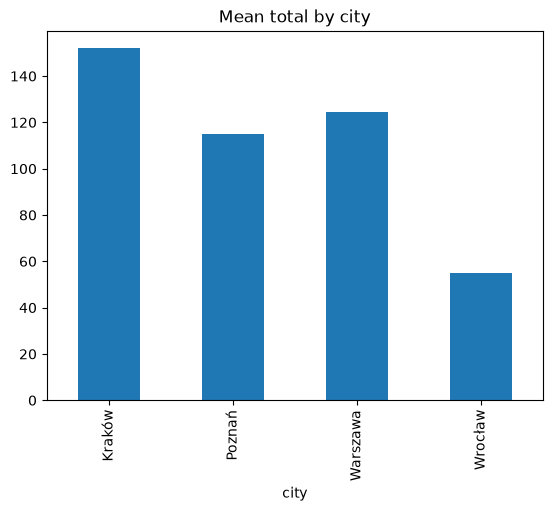

In [21]:
df.groupby("city")["total"].mean().plot(kind="bar", title="Mean total by city");

## Cheat sheet

| Goal | Code |
|---|---|
| read / write CSV | `pd.read_csv("f.csv")`, `df.to_csv("f.csv", index=False)` |
| look | `df.head()`, `df.shape`, `df.info()`, `df.describe()` |
| columns | `df["a"]`, `df[["a", "b"]]` |
| rows | `df.iloc[0:5]`, `df.loc[condition, ["a"]]` |
| filter | `df[(df["a"] > 1) & (df["b"] == "x")]`, `df["a"].isin([...])` |
| sort | `df.sort_values("a", ascending=False)` |
| missing | `df.isna().sum()`, `df.fillna(0)`, `df.dropna()` |
| new column | `df["c"] = df["a"] + df["b"]` |
| count | `df["a"].value_counts()` |
| group | `df.groupby("a")["b"].mean()`, `.agg(["count", "mean"])` |
| join | `df.merge(other, on="key")` |

**Next:** practise with the 30 short tasks in `exercises.ipynb`.